## Conclusion 3: Mann-Whitney Test: Are comments labeled with anger significantly different in length compared with labels with sadness?

H0: Comments labeled with anger are NOT significantly different in length compared with comments labeled with sadness

HA: Comments labeled with anger are significantly different in length compared with comments labeled with sadness

We use a Mann-Whitney U test because we are comparing two groups since we want to determine if there are stastically significant differences on contionous or ordinal dependent varialbe

In [13]:
import pandas as pd
from scipy.stats import mannwhitneyu
import matplotlib.pyplot as plt

df = pd.read_csv("goemotions.csv")

emotion_cols = [
    'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring',
    'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval',
    'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief',
    'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief',
    'remorse', 'sadness', 'surprise', 'neutral'
]

df["word_count"] = df["text"].fillna("").str.split().str.len()

comments = df.groupby("id").agg(
    word_count=("word_count", "first"),
    **{emotion: (emotion, "mean") for emotion in emotion_cols}
).reset_index()

for emotion in emotion_cols:
    comments[emotion] = comments[emotion] >= 0.5

df.head(5)

,text,id,author,subreddit,link_id,parent_id,created_utc,rater_id,example_very_unclear,admiration,...,nervousness,optimism,pride,realization,relief,remorse,sadness,surprise,neutral,word_count
0,That game hurt.,eew5j0j,Brdd9,nrl,t3_ajis4z,t1_eew18eq,1.548381e+09,1,False,0,...,0,0,0,0,0,0,1,0,0,3
1,>sexuality shouldn’t be a grouping category I...,eemcysk,TheGreen888,unpopularopinion,t3_ai4q37,t3_ai4q37,1.548084e+09,37,True,0,...,0,0,0,0,0,0,0,0,0,21
2,"You do right, if you don't care then fuck 'em!",ed2mah1,Labalool,confessions,t3_abru74,t1_ed2m7g7,1.546428e+09,37,False,0,...,0,0,0,0,0,0,0,0,1,10
3,Man I love reddit.,eeibobj,MrsRobertshaw,facepalm,t3_ahulml,t3_ahulml,1.547965e+09,18,False,0,...,0,0,0,0,0,0,0,0,0,4
4,"[NAME] was nowhere near them, he was by the Fa...",eda6yn6,American_Fascist713,starwarsspeculation,t3_ackt2f,t1_eda65q2,1.546669e+09,2,False,0,...,0,0,0,0,0,0,0,0,1,10


            id  word_count  admiration  amusement  anger  annoyance  approval  \
0      eczazk6          17       False      False  False      False      True   
1      eczb07q           9       False      False  False      False     False   
2      eczb4bm          16       False      False  False      False     False   
3      eczb527           5       False      False  False      False     False   
4      eczb6r7          20       False      False  False      False     False   
...        ...         ...         ...        ...    ...        ...       ...   
58006  efhclgb          18       False      False  False      False     False   
58007  efhcm78          10       False      False  False      False     False   
58008  efhcnhz          21       False      False  False      False     False   
58009  efhcreo           2        True      False  False      False     False   
58010  efhcuxi           5       False      False  False      False     False   

       caring  confusion  c

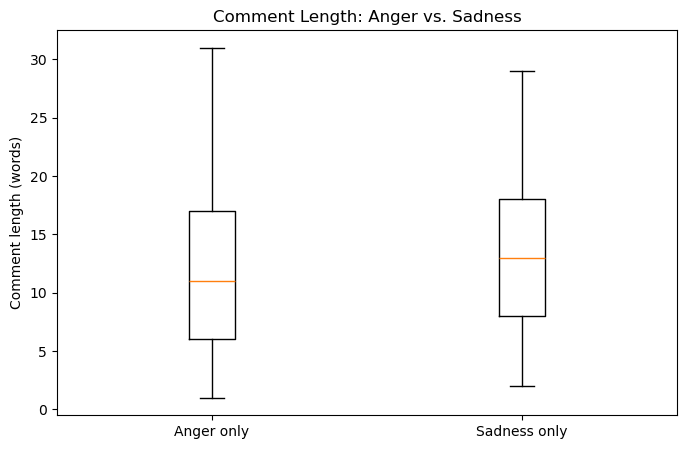

In [ ]:
# here we conduct the Mann Whitney Test
print(comments)

anger = comments[comments["anger"] & ~ comments["sadness"]]["word_count"]
sadness = comments[ comments["sadness"] & ~comments["anger"]]["word_count"]
U, p_value = mannwhitneyu(anger, sadness, alternative="two-sided")

#create the plot and calculate statistics
plt.figure(figsize=(8, 5))
plt.boxplot([anger, sadness], tick_labels=["Anger only", "Sadness only"])
plt.ylabel("Comment length (words)")
plt.title("Comment Length: Anger vs. Sadness")

print("U statistic:", U)
print("P value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis: the distributions differ.")
else:
    print("Fail to reject the null hypothesis: insufficient evidence of a difference.")

Since the p < .05, we reject the null hypothesis, as there is statistical significant evidence that the comments labeled as sadness or anger typically differ significantly in length. The box plot also shows us that comments labeled with sadness have a smaller standard deviation and typically vary less in length compared to comments labeled as anger.